---
# **Traffic Data Analysis**
### Joseph Nicolas
---

## Imports

The necessary libraries required to run this notebook are below.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import sqlite3 as sql
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.cluster import KMeans, AgglomerativeClustering
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from mlxtend.frequent_patterns import apriori, association_rules

# Make sure all columns are visible to us 
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

---
## SQL Setup & Database Schema

First we connect to the SQLite database and list the tables it contains. Each table’s first 5 rows are displayed so we can see the columns and spot any obvious issues before analysis.

In [2]:
# Create a connection to the database within the current directory.
# If the connection fails (e.g., missing file), print a warning and stop gracefully.
try:
    con = sql.connect("accident_data_v1.0.0_2023.db")
except Exception as err:
    print(f"Could not connect to database: {err}")
    con = None

# Only continue if we actually got a connection
if con:
    # Get all the table names in a list 
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", con)['name'].tolist()

    # Loop through each table to display some of its contents
    for table in tables:
        print(f"\n********** {table} table **********")
        display(pd.read_sql_query(f"SELECT * FROM {table}", con).head(5))
else:
    print("Skipping database operations.")


,********** accident table **********


,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,first_road_class,first_road_number,road_type,speed_limit,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
0,2017010001708,2017,010001708,532920.0,196330.0,-0.080107,51.650061,1,1,2,3,05/08/2017,7,03:12,32,E09000010,E09000010,3,105,6,30,0,-1,-1,-1,0,0,4,1,1,0,0,1,1,2,E01001450
1,2017010009342,2017,010009342,526790.0,181970.0,-0.173845,51.522425,1,3,2,1,01/01/2017,1,01:30,1,E09000033,E09000033,3,5,6,30,3,4,6,0,0,0,4,1,2,0,0,1,1,2,E01004702
2,2017010009344,2017,010009344,535200.0,181260.0,-0.052969,51.514096,1,3,3,1,01/01/2017,1,00:30,5,E09000030,E09000030,3,13,6,30,3,4,5,0,0,0,4,1,1,0,0,1,1,2,E01004298
3,2017010009348,2017,010009348,534340.0,193560.0,-0.060658,51.624832,1,3,2,1,01/01/2017,1,01:11,32,E09000010,E09000010,3,1010,1,30,1,4,4,154,0,4,4,2,2,0,0,1,1,2,E01001429
4,2017010009350,2017,010009350,533680.0,187820.0,-0.072372,51.573408,1,2,1,1,01/01/2017,1,01:42,4,E09000012,E09000012,3,107,3,20,6,2,3,10,0,5,4,1,2,0,0,1,1,2,E01001808



,********** casualty table **********


,casualty_index,accident_index,accident_year,accident_reference,vehicle_reference,casualty_reference,casualty_class,sex_of_casualty,age_of_casualty,age_band_of_casualty,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_home_area_type,casualty_imd_decile
0,0,2017010001708,2017,010001708,1,1,2,2,18,4,3,0,0,1,0,0,9,1,2
1,1,2017010001708,2017,010001708,2,2,1,1,19,4,2,0,0,0,0,0,2,-1,-1
2,2,2017010001708,2017,010001708,2,3,2,1,18,4,1,0,0,0,0,0,2,-1,-1
3,3,2017010009342,2017,010009342,1,1,2,2,33,6,3,0,0,1,0,0,9,1,5
4,4,2017010009344,2017,010009344,3,1,1,2,31,6,3,0,0,0,0,0,9,1,5



,********** vehicle table **********


,vehicle_index,accident_index,accident_year,accident_reference,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,vehicle_location_restricted_lane,junction_location,skidding_and_overturning,hit_object_in_carriageway,vehicle_leaving_carriageway,hit_object_off_carriageway,first_point_of_impact,vehicle_left_hand_drive,journey_purpose_of_driver,sex_of_driver,age_of_driver,age_band_of_driver,engine_capacity_cc,propulsion_code,age_of_vehicle,generic_make_model,driver_imd_decile,driver_home_area_type
0,0,2017010001708,2017,010001708,1,9,0,18,1,5,0,0,0,0,0,0,1,1,6,1,24,5,1997,2,1,-1,-1,-1
1,1,2017010001708,2017,010001708,2,2,0,18,1,5,0,0,1,0,0,0,2,1,6,1,19,4,-1,-1,-1,-1,-1,-1
2,2,2017010009342,2017,010009342,1,9,0,18,5,1,0,1,0,0,0,0,2,1,6,1,33,6,1797,8,8,-1,9,1
3,3,2017010009342,2017,010009342,2,9,0,18,5,1,0,1,1,0,0,0,1,1,6,1,40,7,2204,2,12,-1,2,1
4,4,2017010009344,2017,010009344,1,9,0,18,3,7,0,1,0,0,0,0,1,1,6,3,-1,-1,-1,-1,-1,-1,-1,-1



,********** lsoa table **********


,objectid,lsoa01cd,lsoa01nm,lsoa01nmw,shape__area,shape__length,globalid
0,1,E01000001,City of London 001A,City of London 001A,1.298652e+05,2635.772001,68cc6127-1008-4fbe-a16c-78fb089a7c43
1,2,E01000002,City of London 001B,City of London 001B,2.284189e+05,2707.986202,937edbc3-c1bf-4d35-b274-b0a1480a7c09
2,3,E01000003,City of London 001C,City of London 001C,5.905477e+04,1224.774479,2686dcaf-10b9-4736-92af-4788d4feaa69
3,4,E01000004,City of London 001D,City of London 001D,2.544551e+06,10718.466240,3c493140-0b3f-4b9a-b358-22011dc5fb89
4,5,E01000005,City of London 001E,City of London 001E,1.895782e+05,2275.809358,b569093d-788d-41be-816c-d6d7658b2311


The loop prints every table name and a quick sample of its contents.  

You might notice that some columns have `-1` for missing or unknown values, especially in the `vehicle` and `casualty` tables.  
Where those -1 values would cause trouble, we filter them out directly in the SQL queries.

No rows are changed or removed at this point. This is just the first look.

---
## Task 1: When Accidents Happen

Here I look at how accidents in 2018 are distributed across hours of the day and days of the week.\
The goal is to spot the times when accidents are most frequent.

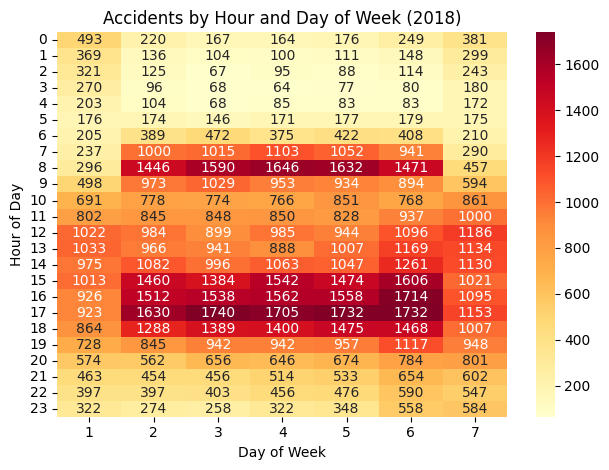

In [3]:
# Get the number of accidents by hour and day_of_week from 2018 only
# day_of_week (STATS20): 1 = Sunday | 2 = Monday | 3 = Tuesday | 4 = Wednesday | 5 = Thursday | 6 = Friday | 7 = Saturday
query_acc = """
SELECT 
    CAST(substr(time, 1, 2) AS INTEGER) AS hour,
    day_of_week,
    COUNT(*) AS accidents
FROM accident
WHERE accident_year = 2018
GROUP BY hour, day_of_week
ORDER BY hour, day_of_week
"""
df_acc = pd.read_sql_query(query_acc, con)

# Create a pivot for the heatmap
heatmap_data = df_acc.pivot(index='hour', columns='day_of_week', values='accidents')

# Plot the heatmap and save it in high resolution
plt.figure()
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Accidents by Hour and Day of Week (2018)')
plt.xlabel('Day of Week')
plt.ylabel('Hour of Day')
plt.tight_layout()
plt.savefig('./accidents_2018.png', dpi=600)
plt.show()

The query counts accidents per hour and weekday in 2018.  
`CAST(substr(time,1,2) AS INTEGER)` extracts the hour as an integer, e.g. `7` from `07:45`.  
We group by that integer hour and `day_of_week`, then pivot into a heatmap.  

No cleaning or filtering was needed: `day_of_week` values are always between 1 and 7, and the `time` column always holds valid hours (0–23).  

The heatmap shows two large sections: the morning rush between 7 and 9, and the late afternoon rush between 15 and 18. Friday has the highest daily total. Weekends see fewer accidents overall, though they still show a midday peak.

---
## Task 2: Motorcycle Accidents

We now isolate motorcycle accidents in 2018 and split them into the four engine‑size categories used in the STATS20 classification: 50cc and under, 51–125cc, 126–500cc, and over 500cc. The heatmaps below show how accident counts are distributed across the hours of the day and days of the week for each group.

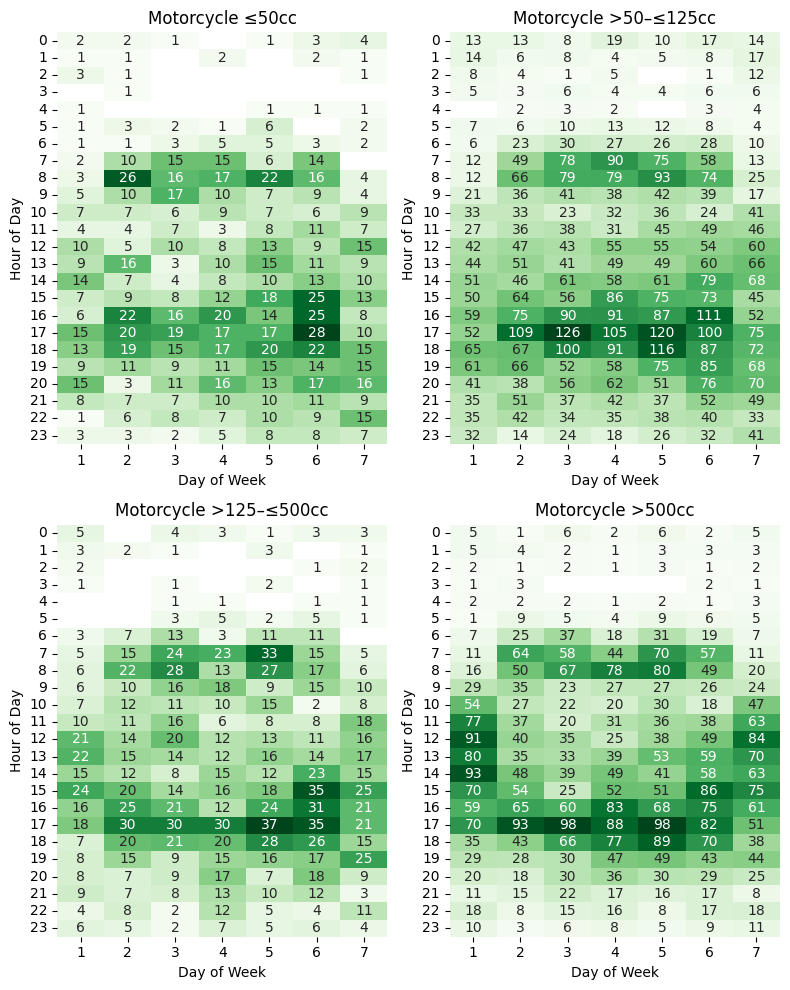

In [4]:
# Get the number of motorcycle accidents by hour and day_of_week from 2018 only
# vehicle_type (STATS20): 2 = ≤50cc | 3 = >50–≤125cc | 4 = >125–≤500cc | 5 = >500cc 
# We drop records vehicle_type is a motorcycle but engine_capacity_cc is -1 (unknown)
query_moto = """
SELECT 
    v.vehicle_type,
    CAST(substr(a.time, 1, 2) AS INTEGER) AS hour,
    a.day_of_week,
    COUNT(*) AS accidents
FROM accident a
JOIN vehicle v ON a.accident_index = v.accident_index
WHERE a.accident_year = 2018
  AND v.vehicle_type IN (2, 3, 4, 5)
  AND v.engine_capacity_cc > 0
GROUP BY v.vehicle_type, hour, a.day_of_week
ORDER BY v.vehicle_type, hour, a.day_of_week
"""
df_moto = pd.read_sql_query(query_moto, con)

# Map numeric vehicle_type codes to readable labels
type_labels = {2: '≤50cc', 3: '>50–≤125cc', 4: '>125–≤500cc', 5: '>500cc'}
df_moto['category'] = df_moto['vehicle_type'].map(type_labels)

# Create a 2×2 grid of subplots so each engine category has its own heatmap
fig, axes = plt.subplots(2, 2, figsize=(8, 10))

# Loop through each vehicle_type code and its corresponding subplot
for ax, cat in zip(axes.flat, type_labels.keys()):
    # Filter the aggregated DataFrame to a single engine size category
    subset = df_moto[df_moto['vehicle_type'] == cat]
    # Pivot table with hours as rows, day of week as columns, and cell value = accident count
    heat = subset.pivot_table(index='hour', columns='day_of_week', values='accidents', aggfunc='sum')
    # Draw the heatmap with green colors for the heatmaps
    sns.heatmap(heat, annot=True, fmt='.0f', cmap='Greens', ax=ax, cbar=False)
    ax.set_title(f'Motorcycle {type_labels[cat]}')
    ax.set_xlabel('Day of Week')
    ax.set_ylabel('Hour of Day')

plt.tight_layout()
plt.savefig('./motorcycles_2018.png', dpi=600)
plt.show()

The query again counts accidents by hour and weekday, but now joins the `vehicle` table and keeps only rows where `vehicle_type` is 2, 3, 4 or 5 and `engine_capacity_cc` is greater than zero (this removes vehicles where the engine size was unknown).

The morning (7‑8) and late‑afternoon (15‑18) commute peaks appear across all engine sizes like they did previously.  
The midday block (10‑14) is notably busier for motorcycles over 500 cc on Saturday and Sunday, which indicates they could be doing more recreational riding.  
No single weekday stands out, though Friday and Saturday evenings show a slight rise across all categories.

---
## Task 3: Pedestrian Accidents 

We now look at pedestrian casualties in 2018. The same hour‑by‑weekday heatmap format is used but now I'm filtering for `casualty_class = 3`.\
Extra checks on `pedestrian_location` and `pedestrian_movement` ensure we only count records where the pedestrian details are properly recorded.

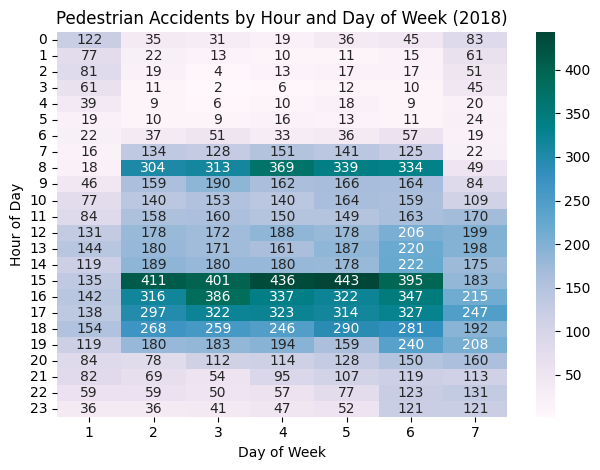

In [5]:
# Get the number of pedestrian accidents by hour and day_of_week from 2018 only
# casualty_class (STATS20): 3 = Pedestrian 
# We also make sure the pedestrian‑specific fields are properly filled by:
# pedestrian_location > 0 and pedestrian_movement > 0 as per the STATS20
query_ped = """
SELECT 
    CAST(substr(a.time, 1, 2) AS INTEGER) AS hour,
    a.day_of_week,
    COUNT(*) AS accidents
FROM accident a
JOIN casualty c ON a.accident_index = c.accident_index
WHERE a.accident_year = 2018
  AND c.casualty_class = 3
  AND c.pedestrian_location > 0
  AND c.pedestrian_movement > 0
GROUP BY hour, a.day_of_week
ORDER BY hour, a.day_of_week
"""
df_ped = pd.read_sql_query(query_ped, con)

# Pivot so each row is an hour, each column a day of the week
heat_ped = df_ped.pivot(index='hour', columns='day_of_week', values='accidents')

# Quick heatmap to show the results
plt.figure()
sns.heatmap(heat_ped, annot=True, fmt='d', cmap='PuBuGn')
plt.title('Pedestrian Accidents by Hour and Day of Week (2018)')
plt.xlabel('Day of Week')
plt.ylabel('Hour of Day')
plt.tight_layout()
plt.savefig('./pedestrians_2018.png', dpi=600)
plt.show()

The query joins `accident` to `casualty`, keeping only rows where `casualty_class = 3` and both `pedestrian_location` and `pedestrian_movement` are greater than zero. This removes any rows where the pedestrian‑specific fields were left empty or coded something invalid like -1. The rest of the logic groups by hour and weekday, then pivots into a heatmap.

The heatmap shows pedestrian accidents follow a timing pattern very similar to what we saw with motorcycles. The same morning (7‑9) and late‑afternoon (15‑18) peaks appear, suggesting that when traffic is heaviest, both motorcycles and pedestrians are exposed to more risk.  At 8 there is also a large number of pedestrian casualties. The afternoon rush (15‑18) also shows up on Saturday, albeit at a lower level than on weekdays. Friday remains the weekday with the highest overall counts, but Monday to Thursday figures are not far behind.

---
## Task 4: Apriori Association Rules 

We use the Apriori algorithm to find combinations of road, weather and location factors that frequently appear together with accident severity. The aim is to see which conditions are most strongly linked to slight, serious or fatal outcomes.

In [6]:
# Fetch the required columns for 2018 directly from the database
query_ap = """
SELECT accident_severity, day_of_week, light_conditions,
       weather_conditions, road_surface_conditions, urban_or_rural_area
FROM accident
WHERE accident_year = 2018
"""
df_ap = pd.read_sql_query(query_ap, con).dropna()

# Replace numeric severity with readable labels
sev_map = {1: 'Fatal', 2: 'Serious', 3: 'Slight'}
df_ap['severity'] = df_ap['accident_severity'].map(sev_map)

# One‑hot encode the condition columns, then add severity dummies separately
df_dummy = pd.get_dummies(
    df_ap.drop(['accident_severity', 'severity'], axis=1),
    columns=['day_of_week', 'light_conditions', 'weather_conditions',
             'road_surface_conditions', 'urban_or_rural_area'],
    prefix_sep='_'
)
severity_dummy = pd.get_dummies(df_ap['severity'], prefix='severity')

# Combine and force boolean type so apriori runs without warnings
df_encoded = pd.concat([df_dummy, severity_dummy], axis=1).astype(bool)

# Mine frequent itemsets with 5% minimum support
frequent_itemsets = apriori(df_encoded, min_support=0.05, use_colnames=True)

# Generate rules where the consequent is a severity label
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
severity_rules = rules[
    rules['consequents'].apply(lambda x: any('severity' in str(i) for i in x))
]

# Top 10 rules by lift
top_rules = severity_rules.sort_values('lift', ascending=False).head(10)
print("Top 10 association rules with accident severity:")
display(top_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

Top 10 association rules with accident severity:


,antecedents,consequents,support,confidence,lift
1443,"(road_surface_conditions_2, urban_or_rural_area_1)","(severity_Slight, weather_conditions_2)",0.054617,0.384038,4.553902
1447,(weather_conditions_2),"(severity_Slight, road_surface_conditions_2, urban_or_rural_area_1)",0.054617,0.523731,4.520537
1444,"(urban_or_rural_area_1, weather_conditions_2)","(severity_Slight, road_surface_conditions_2)",0.054617,0.801388,4.395465
505,(weather_conditions_2),"(severity_Slight, road_surface_conditions_2)",0.081681,0.783251,4.295989
504,(road_surface_conditions_2),"(severity_Slight, weather_conditions_2)",0.081681,0.355024,4.209859
1446,(road_surface_conditions_2),"(severity_Slight, urban_or_rural_area_1, weather_conditions_2)",0.054617,0.237391,4.202758
457,(road_surface_conditions_2),"(severity_Slight, light_conditions_4)",0.058515,0.254333,1.596218
456,(light_conditions_4),"(severity_Slight, road_surface_conditions_2)",0.058515,0.289986,1.590521
2298,"(weather_conditions_1, urban_or_rural_area_1)","(severity_Slight, light_conditions_4, road_surface_conditions_1)",0.077074,0.140621,1.476590
2297,"(light_conditions_4, road_surface_conditions_1)","(severity_Slight, weather_conditions_1, urban_or_rural_area_1)",0.077074,0.639037,1.427604


The code one‑hot encodes the selected 2018 accident columns and mines frequent itemsets with a minimum support of 5%. Association rules are generated and filtered so the consequent always contains a severity label. The top 10 rules are shown ranked by lift.

The strongest rules all point towards `severity_Slight`. The most common pattern is wet or damp road surfaces (`road_surface_conditions_2`) paired with rain (`weather_conditions_2`) and urban areas (`urban_or_rural_area_1`). These conditions rarely lead to fatal or serious outcomes. Instead, they consistently produce slight‑severity accidents. The lift values above 4 mean these combinations are much more likely to appear together than by chance. This suggests that adverse weather and poor road surfaces tend to cause lower‑speed, less severe collisions rather than high‑impact crashes. None of the top rules flagged a strong link to fatal accidents, which is itself an important finding.

---
## Task 5: West Yorkshire Clusters 

We now focus on West Yorkshire accidents in 2018. Three clustering methods: K‑Means, Gaussian Mixture, and Agglomerative are applied to the accident coordinates to see whether the accidents naturally group into distinct geographical areas, and how the algorithms compare.

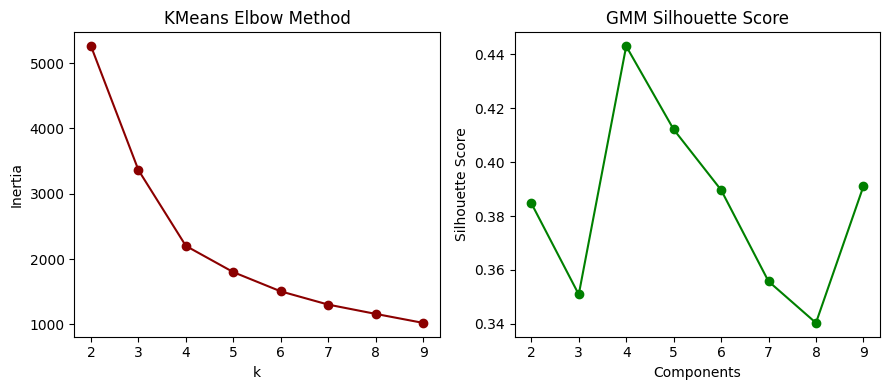

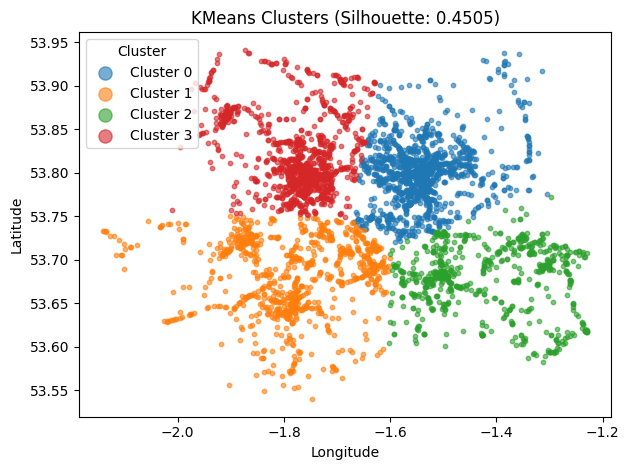

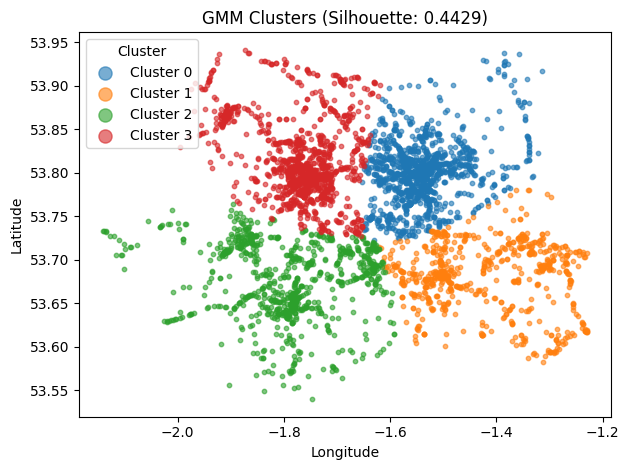

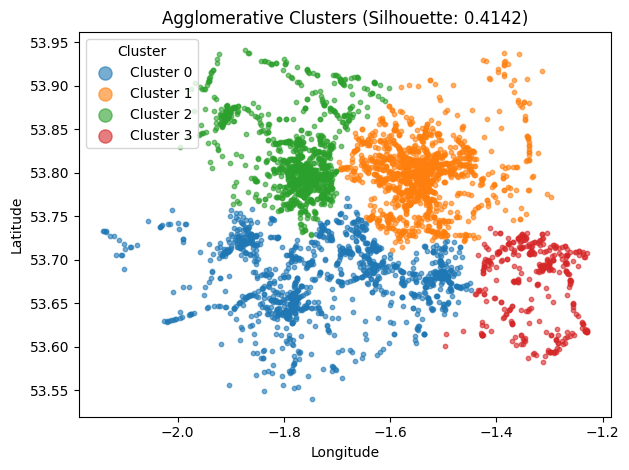

In [7]:
# Pull accidents for West Yorkshire ((STATS20) police_force = 13) in 2018, keep only coordinates
query_wy = """
SELECT longitude, latitude
FROM accident
WHERE accident_year = 2018
  AND police_force = 13
"""
df_wy = pd.read_sql_query(query_wy, con)
df_wy = df_wy.dropna(subset=['longitude', 'latitude'])

# Scale coordinates so clustering algorithms treat both axes equally
scaler = StandardScaler()
coords_scaled = scaler.fit_transform(df_wy[['longitude', 'latitude']])

# Before fitting the final clusters, we run diagnostics to justify the choice of k.
# The elbow method plots KMeans inertia across k values where we pick the bend point.
# GMM silhouette scores measure how well-separated the components are, we pick the highest silhouette score.
inertias, sil_scores = [], []
for k in range(2, 10):
    inertias.append(KMeans(n_clusters=k, random_state=50, n_init=10).fit(coords_scaled).inertia_)
    sil_scores.append(silhouette_score(coords_scaled, GaussianMixture(n_components=k, random_state=50).fit_predict(coords_scaled)))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].plot(range(2, 10), inertias, marker='o', color='darkred')
axes[0].set_title('KMeans Elbow Method')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[1].plot(range(2, 10), sil_scores, marker='o', color='green')
axes[1].set_title('GMM Silhouette Score')
axes[1].set_xlabel('Components')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.savefig('./cluster_diagnostics.png', dpi=600)
plt.show()

# We will try three different clustering algorithms on the same scaled data with the best values
cluster_methods = {
    'KMeans': KMeans(n_clusters=4, random_state=50, n_init=10),
    'GMM': GaussianMixture(n_components=4, random_state=50),
    'Agglomerative': AgglomerativeClustering(n_clusters=4)
}

# Fit each method, store the cluster labels, and plot a scatter map with a legend
for name, model in cluster_methods.items():
    labels = model.fit_predict(coords_scaled)
    df_wy[f'cluster_{name}'] = labels

    # Calculate silhouette score (higher means better separated clusters)
    sil = silhouette_score(coords_scaled, labels)
    # I will display it on the title of the plot

    plt.figure()
    for clust in sorted(np.unique(labels)):
        subset = df_wy[df_wy[f'cluster_{name}'] == clust]
        plt.scatter(subset['longitude'], subset['latitude'],
                    s=10, alpha=0.6, label=f'Cluster {clust}')

    plt.title(f'{name} Clusters (Silhouette: {sil:.4f})')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.legend(markerscale=3, title='Cluster')
    plt.tight_layout()
    plt.savefig(f'./wy_clusters_{name.lower()}.png', dpi=600)
    plt.show()

To pick the number of clusters we first ran KMeans inertia and GMM silhouette for k from 2 to 9.  
The elbow plot bends around k=4, and the GMM silhouette score is highest at 4 components, so we set all three algorithms to use 4 clusters.

We ran KMeans, GMM and Agglomerative clustering on the same scaled coordinates.  
All three returned broadly similar groupings, though the exact boundaries shift a little from one method to the next. That is normal given their different mechanics.

Leeds (latitude 53.80, longitude –1.55) appears as a distinct cluster in every result, which makes sense because it is a busy urban area.  
The clusters indicate that accidents mainly gather around cities.

---
## Task 6: Policing Area Forecasts 

Next is to build time series models to predict weekly accident counts for 2019. Three police forces are chosen: West Yorkshire (England), Gwent (Wales), and Tayside (Scotland). This is to see whether forecasting performance differs across regions. Both a seasonal SARIMAX model and a non‑seasonal ARIMA baseline are fitted on 2017‑2018 data.

/home/joseph/Documents/virtual-environment/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
,  warn('Too few observations to estimate starting parameters%s.'



,--- West Yorkshire (police code 13) ---
,SARIMAX MAE: 13.93
,ARIMA MAE: 13.45


/home/joseph/Documents/virtual-environment/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
,  warn('Too few observations to estimate starting parameters%s.'



,--- Gwent (police code 61) ---
,SARIMAX MAE: 3.25
,ARIMA MAE: 3.27


/home/joseph/Documents/virtual-environment/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
,  warn('Too few observations to estimate starting parameters%s.'



,--- Tayside (police code 93) ---
,SARIMAX MAE: 3.35
,ARIMA MAE: 2.36


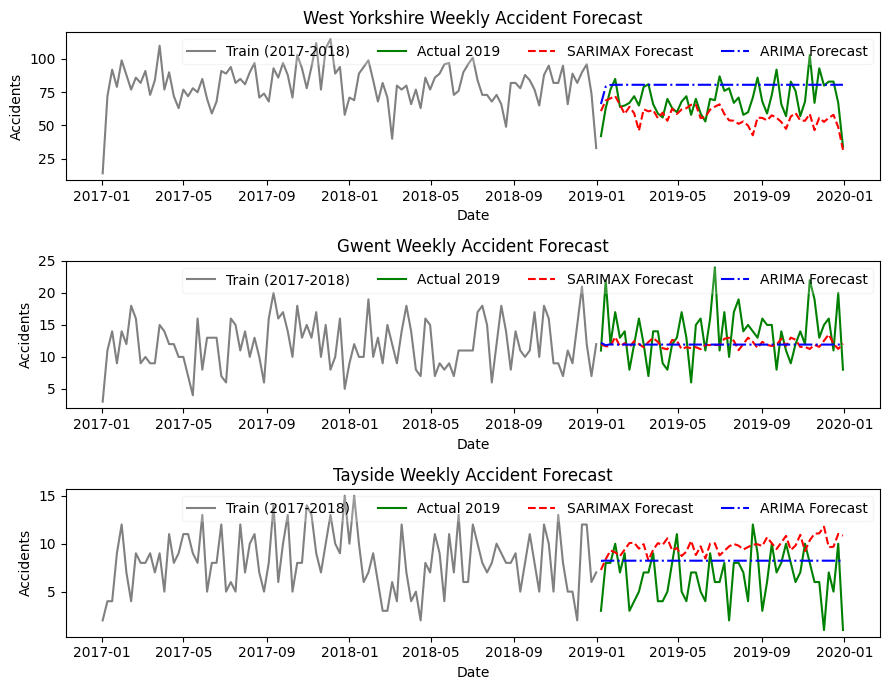

In [8]:
# I chose one police force code for each country: England, Wales, and Scotland
# police_force (STATS20): 13 = West Yorkshire | 61 = Gwent | 93 = Tayside
forces = [13, 61, 93]
force_names = {13: 'West Yorkshire', 61: 'Gwent', 93: 'Tayside'}

def prepare_weekly_ts(force_code):
    """
    Fetch all accidents for a police force, parse dates, and resample to weekly counts.
    Returns a Series with datetime index and weekly frequency (W-MON).
    """
    query = f"""
    SELECT date
    FROM accident
    WHERE police_force = {force_code}
      AND accident_year BETWEEN 2017 AND 2019
    ORDER BY date
    """
    df_raw = pd.read_sql_query(query, con)
    df_raw['date'] = pd.to_datetime(df_raw['date'], format='%d/%m/%Y')
    weekly = df_raw.groupby(pd.Grouper(key='date', freq='W-MON')).size()
    weekly.name = 'weekly_accidents'
    weekly = weekly.asfreq('W-MON', fill_value=0)
    return weekly

# Create a figure with three vertically stacked subplots
fig, axes = plt.subplots(3, 1, figsize=(9, 7))

for ax, force in zip(axes, forces):
    ts = prepare_weekly_ts(force)
    train = ts.loc['2017-01-01':'2018-12-31']
    test  = ts.loc['2019-01-01':'2019-12-31']

    # ********** SARIMAX(1,0,1)(1,0,1,52) **********
    forecast_sarimax = None
    if len(train) >= 104:   # need at least 2 full years for a 52‑week season
        try:
            sarimax_model = SARIMAX(train, order=(1,0,1), seasonal_order=(1,0,1,52),
                                    enforce_stationarity=False, enforce_invertibility=False)
            sarimax_res = sarimax_model.fit(disp=False)
            forecast_sarimax = sarimax_res.get_forecast(steps=len(test)).predicted_mean
        except Exception as e:
            print(f"SARIMAX failed: {e}")

    # ********** Non‑seasonal ARIMA(1,0,1) **********
    forecast_arima = None
    try:
        arima_model = ARIMA(train, order=(1,0,1))
        arima_res = arima_model.fit()
        forecast_arima = arima_res.forecast(steps=len(test))
    except Exception as e:
        print(f"ARIMA failed: {e}")

    # Plot both forecasts against actuals on the current subplot
    ax.plot(train.index, train, color='gray', label='Train (2017-2018)')
    ax.plot(test.index, test, color='green', label='Actual 2019')
    print(f"\n--- {force_names[force]} (police code {force}) ---")

    if forecast_sarimax is not None:
        ax.plot(test.index, forecast_sarimax, color='red', linestyle='--', label='SARIMAX Forecast')
        mae_sarimax = np.mean(np.abs(test - forecast_sarimax))
        print(f"SARIMAX MAE: {mae_sarimax:.2f}")

    if forecast_arima is not None:
        ax.plot(test.index, forecast_arima, color='blue', linestyle='-.', label='ARIMA Forecast')
        mae_arima = np.mean(np.abs(test - forecast_arima))
        print(f"ARIMA MAE: {mae_arima:.2f}")

    ax.set_title(f'{force_names[force]} Weekly Accident Forecast')
    ax.set_xlabel('Date')
    ax.set_ylabel('Accidents')
    ax.legend(loc='upper right', ncols=4, framealpha=0.2)

plt.tight_layout()
plt.savefig('./policing_forecasts.png', dpi=600)
plt.show()

Please ignore the warnings printed during SARIMAX, they are not errors and the code will run as expected. 

The function `prepare_weekly_ts` pulls all accident dates for a force, parses them, and resamples to a regular Monday‑started weekly count. The loop fits a SARIMAX(1,0,1)(1,0,1,52) model (with a weekly seasonality) and an ARIMA(1,0,1) model to each police force, then plots the forecasts alongside the actual 2019 observations.  

The SARIMAX forecasts generally capture the weekly ups and downs better, while ARIMA tends to give flatter predictions. The plots let us compare how much the seasonal pattern helps, and the MAE values printed give a quick gauge of accuracy. Differences between the police forces reflect the varying volatility and size of accident numbers in each area.

---
## Task 7: Top 30 LSOA Forecasts

The last part focuses on the thirty LSOAs in West Yorkshire with the most accidents in the first three months of 2018. Using daily counts from January to June, we train two models: a seasonal SARIMAX and a non‑seasonal ARIMA. These two models will forecast the number of accidents for each day in July.

/home/joseph/Documents/virtual-environment/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
,  warn('Non-stationary starting autoregressive parameters'
,/home/joseph/Documents/virtual-environment/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
,  warn('Non-invertible starting MA parameters found.'


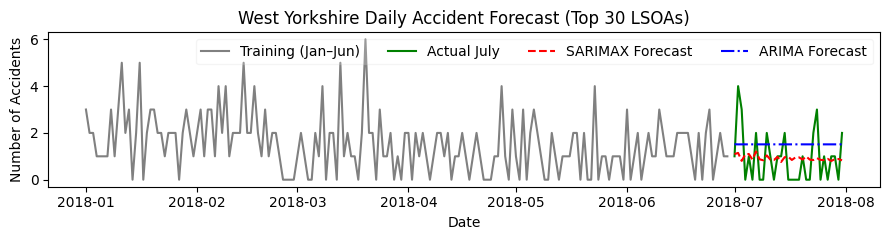

SARIMAX July MAE: 0.84
,ARIMA July MAE: 1.09


In [9]:
# Find the 30 LSOAs with the most accidents in Jan–Mar 2018
query_top30 = """
SELECT lsoa_of_accident_location, COUNT(*) AS accidents
FROM accident
WHERE police_force = 13
  AND accident_year = 2018
  AND substr(date, 4, 2) IN ('01','02','03')
GROUP BY lsoa_of_accident_location
ORDER BY accidents DESC
LIMIT 30
"""
top30_lsoas = pd.read_sql_query(query_top30, con)['lsoa_of_accident_location'].tolist()

# Helper to pull daily accident counts for a given set of LSOAs and months
def get_daily_counts(lsoa_list, months):
    """
    Return a Series of daily accident counts for the supplied LSOAs and months (2018).
    The result is reindexed to cover every calendar day in the month range, filling missing days with 0.
    """
    # Build a comma-separated string of LSOA codes for the SQL IN clause
    lsoa_str = "','".join(lsoa_list)
    month_str = "','".join(months)
    query = f"""
    SELECT date, COUNT(*) AS daily_accidents
    FROM accident
    WHERE police_force = 13
      AND accident_year = 2018
      AND lsoa_of_accident_location IN ('{lsoa_str}')
      AND substr(date, 4, 2) IN ('{month_str}')
    GROUP BY date
    ORDER BY date
    """
    df = pd.read_sql_query(query, con)
    df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
    df = df.set_index('date').sort_index()
    # Ensure every day is present (fill missing days with 0)
    full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='D')
    df = df.reindex(full_range, fill_value=0)
    return df['daily_accidents']

# Training data: daily counts for Jan–Jun 2018
train_daily = get_daily_counts(top30_lsoas, ['01','02','03','04','05','06'])

# ********** SARIMAX(1,0,1)(1,0,1,7) – daily seasonality **********
sarimax_daily = SARIMAX(train_daily,
                        order=(1,0,1),
                        seasonal_order=(1,0,1,7),
                        enforce_stationarity=False,
                        enforce_invertibility=False)
sarimax_daily_res = sarimax_daily.fit(disp=False)
forecast_sarimax = sarimax_daily_res.get_forecast(steps=31).predicted_mean
forecast_sarimax.index = pd.date_range(start='2018-07-01', end='2018-07-31', freq='D')

# ********** ARIMA(1,0,1) – no seasonality **********
arima_daily = ARIMA(train_daily, order=(1,0,1))
arima_daily_res = arima_daily.fit()
forecast_arima = arima_daily_res.forecast(steps=31)
forecast_arima.index = forecast_sarimax.index

# Actual July 2018 counts for comparison (same LSOAs)
actual_july = get_daily_counts(top30_lsoas, ['07'])

# Plot
plt.figure(figsize=(9, 2.5))
plt.plot(train_daily.index, train_daily, color='gray', label='Training (Jan–Jun)')
plt.plot(actual_july.index, actual_july, color='green', label='Actual July')
plt.plot(forecast_sarimax.index, forecast_sarimax, color='red', linestyle='--', label='SARIMAX Forecast')
plt.plot(forecast_arima.index, forecast_arima, color='blue', linestyle='-.', label='ARIMA Forecast')
plt.title('West Yorkshire Daily Accident Forecast (Top 30 LSOAs)')
plt.xlabel('Date')
plt.ylabel('Number of Accidents')
plt.legend(loc='upper right', ncols=4, framealpha=0.2) # put the caption on the right and is more transparent
plt.tight_layout()
plt.savefig('./lsoa_forecast_July.png', dpi=600)
plt.show()

# Mean absolute error for each model
mae_sarimax = np.mean(np.abs(actual_july - forecast_sarimax))
mae_arima   = np.mean(np.abs(actual_july - forecast_arima))
print(f"SARIMAX July MAE: {mae_sarimax:.2f}")
print(f"ARIMA July MAE: {mae_arima:.2f}")

The function `get_daily_counts` avoids repeating the same query logic: it joins LSOA codes and months into the SQL and returns a clean daily series with no missing days. The top 30 LSOAs are identified from January to March, then their aggregated counts for January to June become the training set.

Two models are fitted: a SARIMAX(1,0,1)(1,0,1,7), and an ARIMA(1,0,1) without seasonality. SARIMAX can pick up the weekly rhythm (e.g., fewer accidents on weekends), while ARIMA just captures the overall level and short‑term persistence. The plot shows both forecasts overlaid on the actual July values, and the MAE gives a simple accuracy comparison.

Ignoring any warnings during fitting (they are not errors), the seasonal model usually tracks the day‑of‑week pattern better, while ARIMA stays flatter. Differences between the two models highlight how much the weekly cycle matters for these high‑incident LSOAs.

---
# End
---